In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

np.random.seed(37)  # For reproducibility
#A1, a
# Parameters
nu = 5
mu = 1
sigma = 0.01
n = 700
p = 0.975
q = 0.95

# Calculate the true 97.5% quantile
true_quantile = stats.t.ppf(p, df=nu, loc=mu, scale=sigma)

# Find the order statistic indices using the binomial distribution
r = 1 - p
alpha = 1 - q

j = 1
while stats.binom.cdf(j - 1, n, r) <= alpha / 2:
    j += 1

i = 1
while stats.binom.cdf(i - 1, n, r) < 1 - alpha / 2:
    i += 1

# Generate a sample and sort it in ascending order
sample = stats.t.rvs(df=nu, loc=mu, scale=sigma, size=n)
sorted_sample = np.sort(sample)

# Construct the confidence interval
lower = sorted_sample[n - i]
upper = sorted_sample[n - j+1]

# Calculate the actual coverage probability
lower_tail = 1 - stats.binom.cdf(i - 1, n, r)
upper_tail = stats.binom.cdf(j - 1, n, r)
coverage = 1 - lower_tail - upper_tail

# Print results
print("True quantile:", true_quantile)
print("Order statistics: i =", i -1, ", j =", j-2)
print("Confidence interval:", (lower, upper))
print("Coverage probability:", coverage)

# Check whether the interval contains the true quantile
print("Contains true quantile:", lower <= true_quantile <= upper)


True quantile: 1.0257058183563632
Order statistics: i = 26 , j = 9
Confidence interval: (np.float64(1.02473051640241), np.float64(1.0333053075029583))
Coverage probability: 0.9434529721239769
Contains true quantile: True


Theoretical VaR: 0.2570581835636321


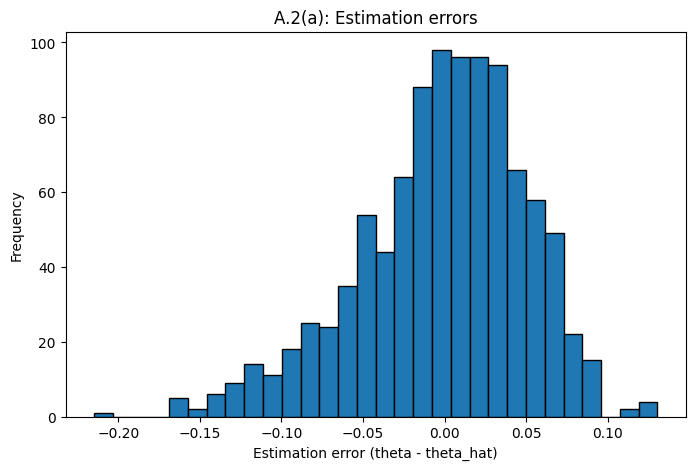

In [42]:

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

np.random.seed(37)  # For reproducibility

# --------------------------------------------------
# Common parameters
# --------------------------------------------------

nu = 5
mu = 1
sigma = 0.01
V0 = 10
p = 0.975
q = 0.95
alpha = 1 - q


# --------------------------------------------------
# A.2(a): Theoretical VaR and estimation errors
# --------------------------------------------------

# Calculate the theoretical 2.5% quantile of returns
q_R = stats.t.ppf(p, df=nu, loc=mu, scale=sigma)

# Calculate the theoretical VaR
theta = V0 * (q_R - 1)

print("Theoretical VaR:", theta)

# Number of simulations and observations per simulation
N = 1000
n = 100

# Store the estimation errors
errors_a = []

for repetition in range(N):

    # Generate 100 independent returns
    returns = stats.t.rvs(df=nu, loc=mu, scale=sigma, size=n)

    # Convert returns into future net values
    X = V0 * (returns - 1)

    # Estimate VaR using the empirical 2.5% quantile
    theta_hat = -np.quantile(X, 1-p, method="inverted_cdf")

    # Calculate the estimation error
    errors_a.append(theta - theta_hat)

# Plot the histogram of estimation errors
plt.figure(figsize=(8, 5))
plt.hist(errors_a, bins=30, edgecolor="black")
plt.xlabel("Estimation error (theta - theta_hat)")
plt.ylabel("Frequency")
plt.title("A.2(a): Estimation errors")
plt.show()



Observed VaR estimate: 0.2686574325104152


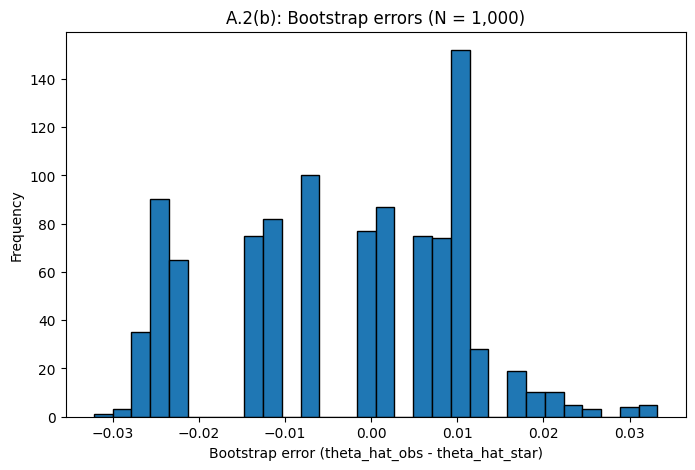

In [46]:

# --------------------------------------------------
# A.2(b): Bootstrap with 1,000 simulations
# --------------------------------------------------
np.random.seed(37) 
# Generate 700 historical observations
n = 700
returns_obs = stats.t.rvs(df=nu, loc=mu, scale=sigma, size=n)

# Convert historical returns into net values
X_obs = V0 * (returns_obs - 1)

# Calculate the empirical VaR from the historical data
theta_hat_obs = -np.quantile(X_obs, 1-p, method="inverted_cdf")

print("Observed VaR estimate:", theta_hat_obs)

# Number of bootstrap simulations
N_boot = 1000

# Store the bootstrap estimation errors
bootstrap_errors_b = []

for repetition in range(N_boot):

    # Draw a bootstrap sample with replacement
    X_star = np.random.choice(X_obs, size=n, replace=True)

    # Calculate the VaR estimate from the bootstrap sample
    theta_hat_star = -np.quantile(X_star, 1-p, method="inverted_cdf")

    # Calculate the difference between the observed and bootstrap estimates
    bootstrap_errors_b.append(theta_hat_obs - theta_hat_star)

# Plot the histogram of bootstrap errors
plt.figure(figsize=(8, 5))
plt.hist(bootstrap_errors_b, bins=30, edgecolor="black")
plt.xlabel("Bootstrap error (theta_hat_obs - theta_hat_star)")
plt.ylabel("Frequency")
plt.title("A.2(b): Bootstrap errors (N = 1,000)")
plt.show()

Observed VaR estimate: 0.2686574325104152


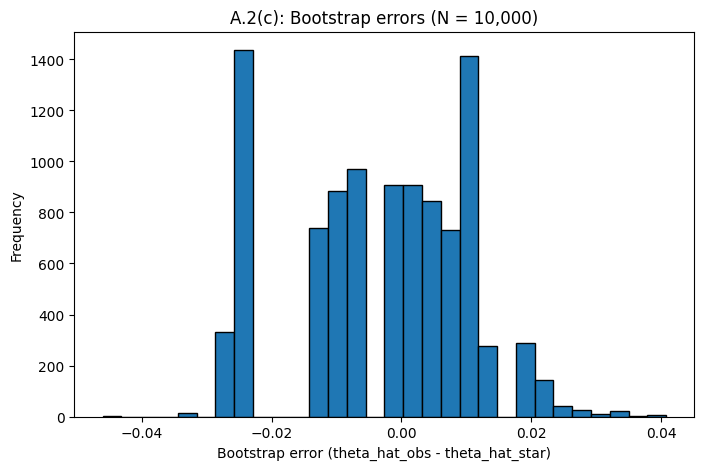

In [ ]:


# --------------------------------------------------
# A.2(c): Bootstrap with 10,000 simulations
# --------------------------------------------------

# Use the same historical observations as in part (b)
np.random.seed(37) 
# Generate 700 historical observations
n = 700
returns_obs = stats.t.rvs(df=nu, loc=mu, scale=sigma, size=n)

# Convert historical returns into net values
X_obs = V0 * (returns_obs - 1)

# Calculate the empirical VaR from the historical data
theta_hat_obs = -np.quantile(X_obs, 1-p, method="inverted_cdf")

print("Observed VaR estimate:", theta_hat_obs)

# Number of bootstrap simulations
N_boot = 10000

# Store the bootstrap estimation errors
bootstrap_errors_b = []

for repetition in range(N_boot):

    # Draw a bootstrap sample with replacement
    X_star = np.random.choice(X_obs, size=n, replace=True)

    # Calculate the VaR estimate from the bootstrap sample
    theta_hat_star = -np.quantile(X_star, 1-p, method="inverted_cdf")

    # Calculate the difference between the observed and bootstrap estimates
    bootstrap_errors_b.append(theta_hat_obs - theta_hat_star)

# Plot the histogram of bootstrap errors
plt.figure(figsize=(8, 5))
plt.hist(bootstrap_errors_b, bins=30, edgecolor="black")
plt.xlabel("Bootstrap error (theta_hat_obs - theta_hat_star)")
plt.ylabel("Frequency")
plt.title("A.2(c): Bootstrap errors (N = 10,000)")
plt.show()
#Comparing A.2(b) and A.2(c), we observe that increasing the number of 
# bootstrap simulations from 1,000 to 10,000 gives a more detailed representation 
# of the bootstrap error distribution. The distributions contain several distinct 
# peaks and are not particularly smooth or symmetric. This is partly because the 
# bootstrap samples are drawn from the original empirical dataset, and the inverted 
# empirical CDF quantile estimator can only select values from that dataset.Using more bootstrap
#  simulations does not provide additional historical information, but it improves the numerical 
# approximation of the bootstrap distribution.


True VaR: 0.25705818356363097


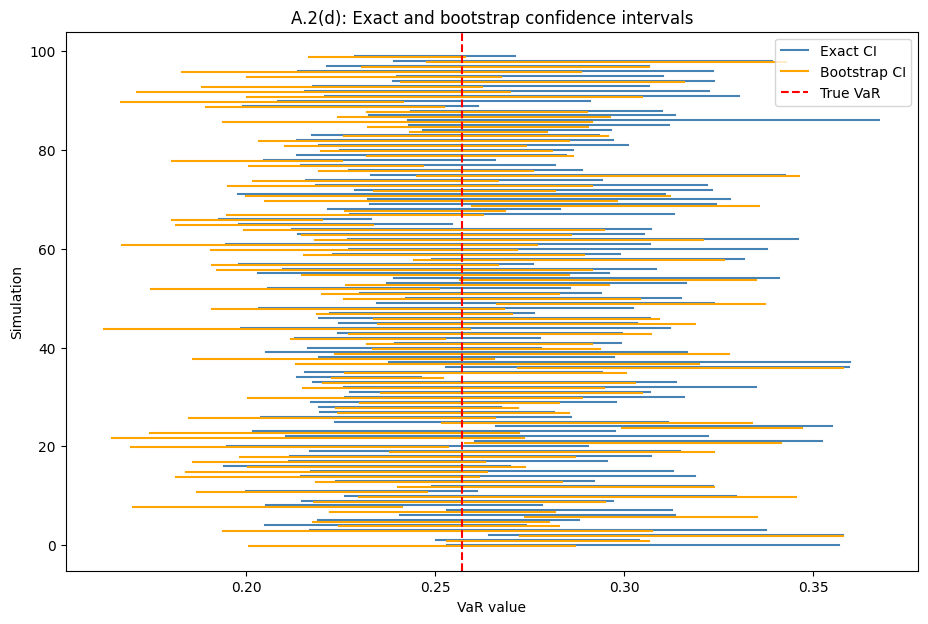

Exact intervals containing true VaR: 94 out of 100
Bootstrap intervals containing true VaR: 81 out of 100
Exact empirical coverage: 0.94
Bootstrap empirical coverage: 0.81


In [ ]:

# --------------------------------------------------
# A.2(d): Exact and bootstrap confidence intervals
# --------------------------------------------------

# Import libraries
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Set random seed for reproducibility
np.random.seed(37)

# Parameters
nu = 5
mu = 1
sigma = 0.01
V0 = 10

n = 700
p = 0.975
q = 0.95

K = 100
N_boot = 1000

# Calculate the true VaR
theta = -V0 * (stats.t.ppf(1-p, df=nu, loc=mu, scale=sigma) - 1)

print("True VaR:", theta)


# Function to calculate an exact confidence interval for VaR
def exact_var_ci(sample, p, confidence):

    n = len(sample)
    alpha = 1 - confidence
    tail_probability = 1 - p

    # Find the order statistic indices using the binomial distribution
    j = 1
    while stats.binom.cdf(j - 1, n, tail_probability) <= alpha / 2:
        j += 1

    i = 1
    while stats.binom.cdf(i - 1, n, tail_probability) < 1 - alpha / 2:
        i += 1

    # Sort the sample in ascending order
    sorted_sample = np.sort(sample)

    # Reverse and negate the endpoints to obtain the VaR interval
    lower = -sorted_sample[i - 1]
    upper = -sorted_sample[j - 1-1]

    return lower, upper


# Store the exact and bootstrap confidence intervals
exact_intervals = []
bootstrap_intervals = []

# Repeat the procedure K times
for repetition in range(K):

    # Generate a new historical dataset
    returns_obs = stats.t.rvs(
        df=nu, loc=mu, scale=sigma, size=n
    )

    # Convert returns into net values
    X_obs = V0 * (returns_obs - 1)

    # Calculate the exact confidence interval
    exact_ci = exact_var_ci(X_obs, p, q)
    exact_intervals.append(exact_ci)

    # Calculate the empirical VaR from the historical data
    theta_hat_obs = -np.quantile(
        X_obs, 1-p, method="inverted_cdf"
    )

    # Store bootstrap estimation errors
    bootstrap_errors = []

    # Generate N_boot bootstrap samples
    for b in range(N_boot):

        # Draw a sample with replacement
        X_star = np.random.choice(X_obs, size=n, replace=True)

        # Calculate the bootstrap VaR estimate
        theta_hat_star = -np.quantile(
            X_star, 1-p, method="inverted_cdf"
        )

        # Calculate the bootstrap error
        bootstrap_errors.append(theta_hat_obs - theta_hat_star)

    # Construct the basic bootstrap confidence interval
    lower = theta_hat_obs + np.quantile(bootstrap_errors, 0.025)
    upper = theta_hat_obs + np.quantile(bootstrap_errors, 0.975)

    bootstrap_intervals.append((lower, upper))


# Convert the intervals into NumPy arrays
exact_intervals = np.array(exact_intervals)
bootstrap_intervals = np.array(bootstrap_intervals)


# Plot both sets of confidence intervals
plt.figure(figsize=(11, 7))

for repetition in range(K):

    # Plot the exact confidence interval
    plt.plot(
        exact_intervals[repetition],
        [repetition, repetition],
        color="steelblue",
        label="Exact CI" if repetition == 0 else ""
    )

    # Plot the bootstrap confidence interval slightly below it
    plt.plot(
        bootstrap_intervals[repetition],
        [repetition - 0.25, repetition - 0.25],
        color="orange",
        label="Bootstrap CI" if repetition == 0 else ""
    )

# Plot the true VaR
plt.axvline(
    theta,
    color="red",
    linestyle="--",
    label="True VaR"
)

plt.xlabel("VaR value")
plt.ylabel("Simulation")
plt.title("A.2(d): Exact and bootstrap confidence intervals")
plt.legend()
plt.show()


# Calculate coverage of both methods
exact_coverage = sum(
    lower <= theta <= upper for lower, upper in exact_intervals
)

bootstrap_coverage = sum(
    lower <= theta <= upper for lower, upper in bootstrap_intervals
)

print("Exact intervals containing true VaR:", exact_coverage, "out of", K)
print("Bootstrap intervals containing true VaR:", bootstrap_coverage, "out of", K)
print("Exact empirical coverage:", exact_coverage / K)
print("Bootstrap empirical coverage:", bootstrap_coverage / K)


### Uppgift B

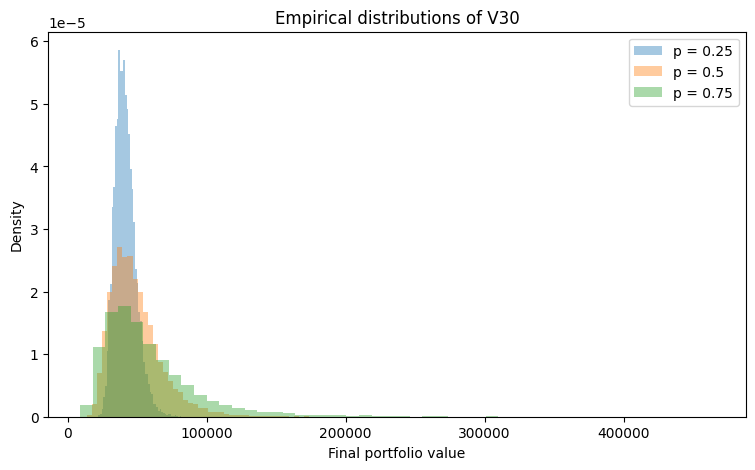

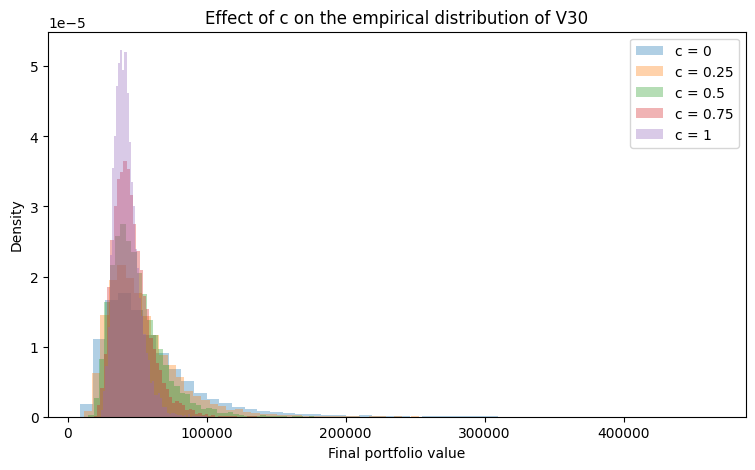

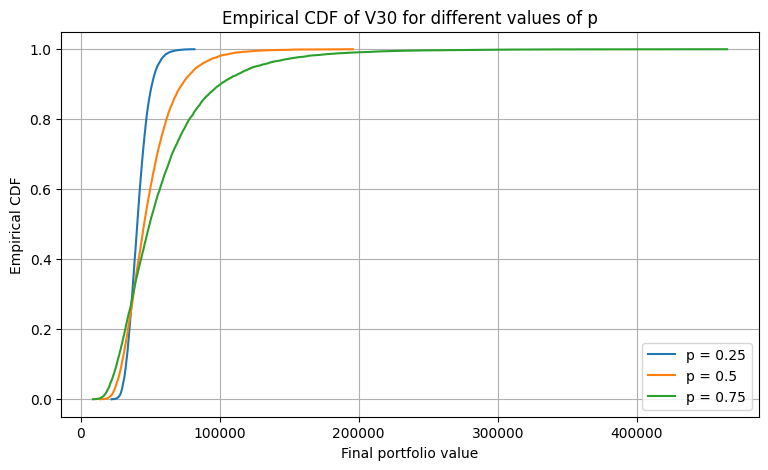

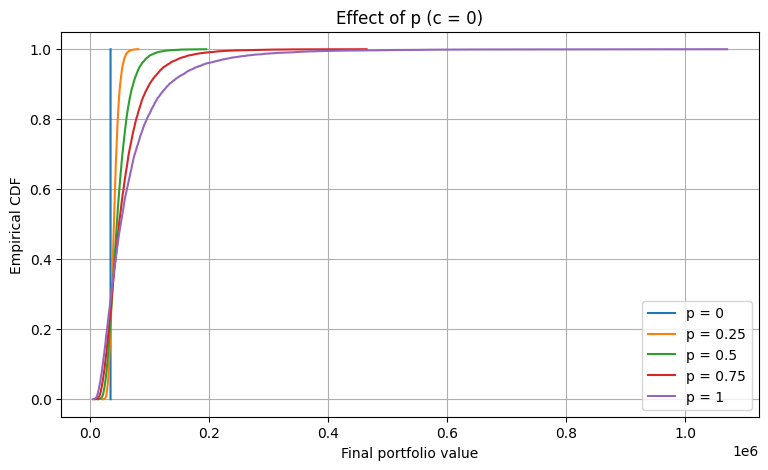

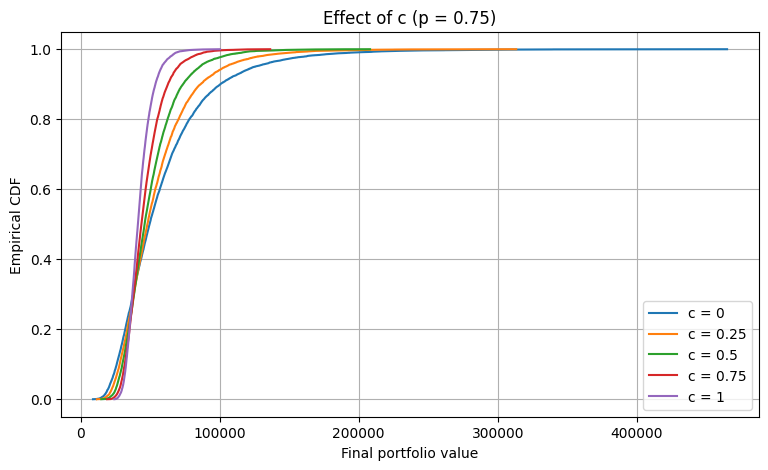

p=0, c=0: Mean=35161.10, Std=0.00, 1%-quantile=35161.10
p=0, c=0.25: Mean=35161.10, Std=0.00, 1%-quantile=35161.10
p=0, c=0.5: Mean=35161.10, Std=0.00, 1%-quantile=35161.10
p=0, c=0.75: Mean=35161.10, Std=0.00, 1%-quantile=35161.10
p=0, c=1: Mean=35161.10, Std=0.00, 1%-quantile=35161.10
p=0.25, c=0: Mean=41497.28, Std=7506.99, 1%-quantile=27932.70
p=0.25, c=0.25: Mean=40415.11, Std=5992.93, 1%-quantile=29166.13
p=0.25, c=0.5: Mean=39363.00, Std=4600.02, 1%-quantile=30445.46
p=0.25, c=0.75: Mean=38340.14, Std=3355.63, 1%-quantile=31547.49
p=0.25, c=1: Mean=37345.73, Std=2345.33, 1%-quantile=32548.50
p=0.5, c=0: Mean=49216.64, Std=18791.48, 1%-quantile=21708.44
p=0.5, c=0.25: Mean=46643.98, Std=14483.38, 1%-quantile=23917.82
p=0.5, c=0.5: Mean=44212.63, Std=10762.79, 1%-quantile=26151.32
p=0.5, c=0.75: Mean=41914.97, Std=7627.20, 1%-quantile=28169.99
p=0.5, c=1: Mean=39743.75, Std=5197.23, 1%-quantile=30136.57
p=0.75, c=0: Mean=58633.20, Std=36240.60, 1%-quantile=16729.62
p=0.75, c=0.25:

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# Simulation settings
n = 10000
T = 30

# Generate random numbers
np.random.seed(37)
Z = np.random.normal(0, 1, size=(n, T))

# Parameters
mu_values = [0.01, 0.03, 0.05]
sigma_values = [0.10, 0.20, 0.30]
p_values = [0, 0.25, 0.50, 0.75, 1]
c_values = [0, 0.25, 0.50, 0.75, 1]

def simulate_portfolio(Z, mu, sigma, p, c):
    n, T = Z.shape
    V = np.zeros(n)

    for k in range(T):
        alpha = p * (1 - c * k / T)

        A = alpha * np.exp(mu + sigma * Z[:, k]) \
            + (1 - alpha) * np.exp(0.01)

        V = (V + 1000) * A

    return V

# Save the results in a dictionary
results = {}

for mu in mu_values:
    for sigma in sigma_values:
        for p in p_values:
            for c in c_values:

                V30 = simulate_portfolio(Z, mu, sigma, p, c)

                results[(mu, sigma, p, c)] = V30

# Plot values for p
plt.figure(figsize=(9, 5))

for p in [0.25, 0.5, 0.75]:
    V30 = results[(0.03, 0.20, p, 0)]

    plt.hist(V30, bins=50, density=True,
             alpha=0.4, label=f"p = {p}")

plt.xlabel("Final portfolio value")
plt.ylabel("Density")
plt.title("Empirical distributions of V30")
plt.legend()
plt.show()
plt.close()


# Plot distributions for different values of c
plt.figure(figsize=(9, 5))

for c in c_values:
    V30 = results[(0.03, 0.20, 0.75, c)]

    plt.hist(V30, bins=50, density=True,
             alpha=0.35, label=f"c = {c}")

plt.xlabel("Final portfolio value")
plt.ylabel("Density")
plt.title("Effect of c on the empirical distribution of V30")
plt.legend()
plt.show()
plt.close()


# Plot empirical CDFs for different values of p

plt.figure(figsize=(9, 5))

for p in [0.25, 0.5, 0.75]:
    V30 = results[(0.03, 0.20, p, 0)]

    sorted_V = np.sort(V30)
    empirical_cdf = np.arange(1, n + 1) / n

    plt.plot(sorted_V, empirical_cdf, label=f"p = {p}")

plt.xlabel("Final portfolio value")
plt.ylabel("Empirical CDF")
plt.title("Empirical CDF of V30 for different values of p")
plt.legend()
plt.grid()
plt.show()
plt.close()


Optimal portfolio
-------------------------------------------------------
Minimum required 1%-quantile: $25,000.00
Optimal p:                    0.97
Optimal c:                    0.92
Expected final wealth:        $46,448.21
1%-quantile:                  $25,008.03
Standard deviation:           $14,343.31
-------------------------------------------------------


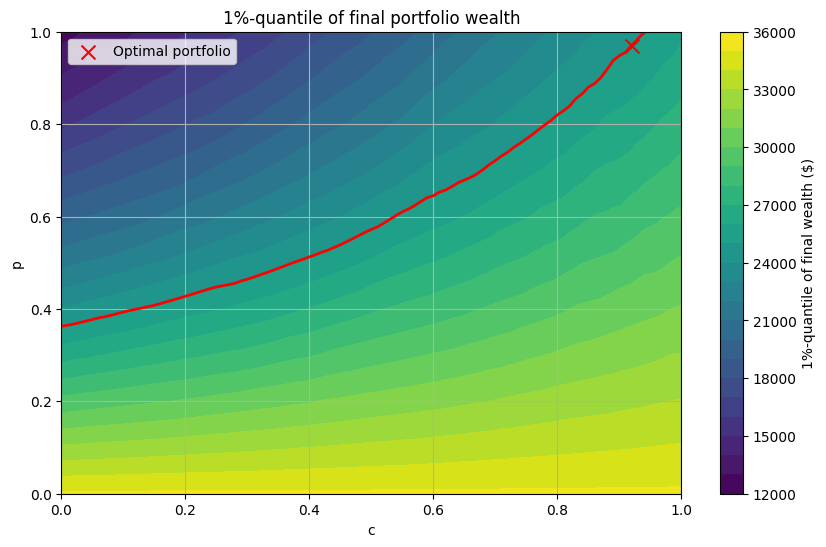

In [43]:

# Part B(b): Grid search and constrained optimisation

import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Parameters
# --------------------------------------------------

mu = 0.03
sigma = 0.20

n = 10000
T = 30

r = 0.01
deposit = 1000

# Minimum acceptable 1%-quantile
G = 25000

# Generate random numbers (same sample for every portfolio)
np.random.seed(37)
Z = np.random.standard_normal((n, T))


# --------------------------------------------------
# 2. Portfolio simulation function
# --------------------------------------------------

def simulate_pension(mu, sigma, p, c, Z):

    n, T = Z.shape
    V = np.zeros(n)

    for k in range(T):

        # Fraction invested in stocks
        alpha = p * (1 - c * k / T)

        # Stock return
        R = np.exp(mu + sigma * Z[:, k])

        # Combined stock and bond return
        A = alpha * R + (1 - alpha) * np.exp(r)

        # Add yearly deposit and update portfolio value
        V = (V + deposit) * A

    return V


# --------------------------------------------------
# 3. Parameter grid
# --------------------------------------------------

p_values = np.linspace(0, 1, 101)
c_values = np.linspace(0, 1, 101)

# Matrices for storing results
mean_values = np.zeros((len(p_values), len(c_values)))
quantile_values = np.zeros((len(p_values), len(c_values)))
std_values = np.zeros((len(p_values), len(c_values)))


# --------------------------------------------------
# 4. Simulate all combinations of p and c
# --------------------------------------------------

for i, p in enumerate(p_values):

    for j, c in enumerate(c_values):

        V30 = simulate_pension(mu, sigma, p, c, Z)

        # Calculate statistics
        mean_values[i, j] = np.mean(V30)
        quantile_values[i, j] = np.quantile(V30, 0.01)
        std_values[i, j] = np.std(V30)


# --------------------------------------------------
# 5. Constrained optimisation
# --------------------------------------------------

# Check which portfolios satisfy the 1%-quantile constraint
feasible = quantile_values >= G

if not np.any(feasible):

    print("No feasible strategy found.")

else:

    # Exclude portfolios that violate the constraint
    objective = np.where(feasible, mean_values, -np.inf)

    # Find the portfolio with the highest expected value
    best_index = np.unravel_index(
        np.argmax(objective),
        objective.shape
    )

    # Extract optimal parameters and statistics
    p_opt = p_values[best_index[0]]
    c_opt = c_values[best_index[1]]

    mean_opt = mean_values[best_index]
    quantile_opt = quantile_values[best_index]
    std_opt = std_values[best_index]

    # Print results
    print("Optimal portfolio")
    print("-" * 55)
    print(f"Minimum required 1%-quantile: ${G:,.2f}")
    print(f"Optimal p:                    {p_opt:.2f}")
    print(f"Optimal c:                    {c_opt:.2f}")
    print(f"Expected final wealth:        ${mean_opt:,.2f}")
    print(f"1%-quantile:                  ${quantile_opt:,.2f}")
    print(f"Standard deviation:           ${std_opt:,.2f}")
    print("-" * 55)


# --------------------------------------------------
# 6. Plot the 1%-quantile for all portfolios
# --------------------------------------------------

plt.figure(figsize=(10, 6))

contour = plt.contourf(
    c_values,
    p_values,
    quantile_values,
    levels=25,
    cmap="viridis"
)

plt.colorbar(contour, label="1%-quantile of final wealth ($)")

# Draw the boundary corresponding to the constraint
plt.contour(
    c_values,
    p_values,
    quantile_values,
    levels=[G],
    colors="red",
    linewidths=2
)

# Mark the optimal portfolio
if np.any(feasible):
    plt.scatter(
        c_opt,
        p_opt,
        color="red",
        marker="x",
        s=100,
        label="Optimal portfolio"
    )

plt.xlabel("c")
plt.ylabel("p")
plt.title("1%-quantile of final portfolio wealth")
plt.legend()
plt.grid()
plt.show()
V30_b = simulate_pension(mu, sigma, p_opt, c_opt, Z)


Part B(c) - Traditional life insurance
--------------------------------------
Mean final value: $36,814.41
1% quantile:      $33,614.47
Standard deviation: $2,965.60


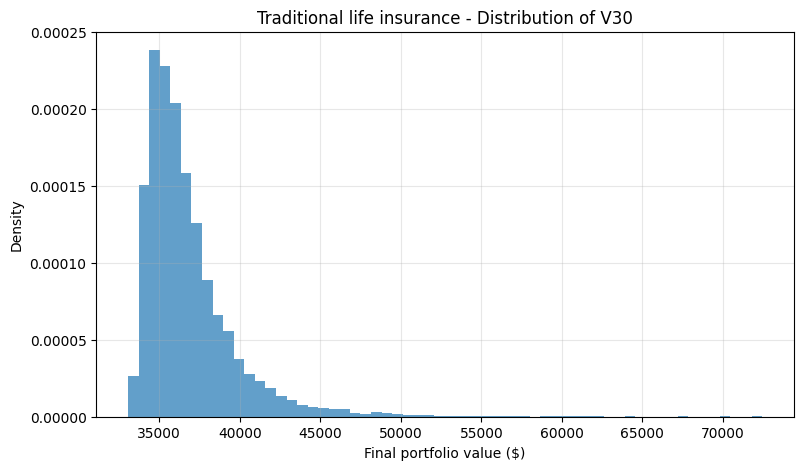

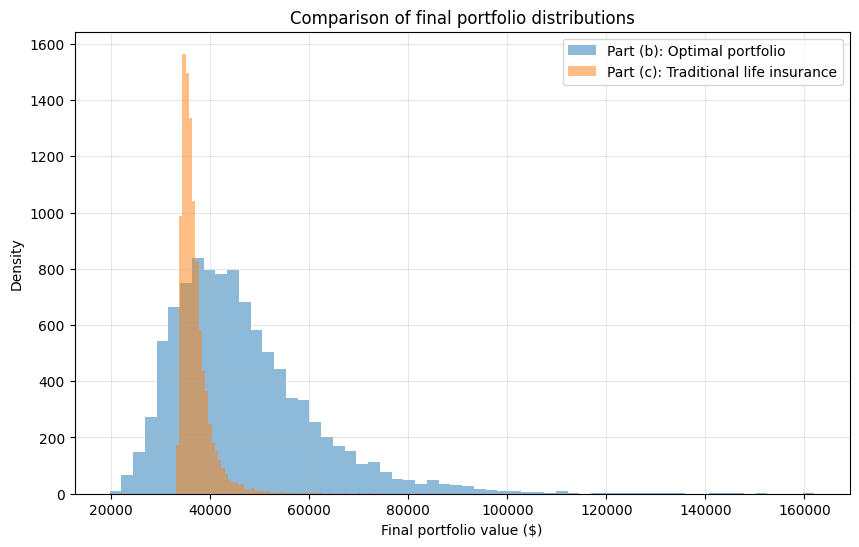

In [46]:

import numpy as np
import matplotlib.pyplot as plt

# Parameters
mu = 0.03
sigma = 0.20
n = 10000
T = 30

deposit = 1000
r = 0.01
r_bar = 0.005

# Generate independent standard normal variables
np.random.seed(37)
Z = np.random.standard_normal((n, T))


# Simulate the traditional life insurance strategy
def simulate_life_insurance(mu, sigma, Z):

    n, T = Z.shape
    V = np.zeros(n)

    for k in range(1, T + 1):

        # Guaranteed amount after year k
        G = deposit * np.sum(np.exp(r_bar * np.arange(1, k + 1)))

        # Amount invested in the bank account
        bank = G * np.exp(-r)

        # Amount invested in stocks
        stock = V + deposit - bank

        # Stock return during year k
        R = np.exp(mu + sigma * Z[:, k - 1])

        # Portfolio value at the end of year k
        V = G + stock * R

    return V


# Run the simulation
V30 = simulate_life_insurance(mu, sigma, Z)


# Calculate results
mean_value = np.mean(V30)
quantile_01 = np.quantile(V30, 0.01)
std_value = np.std(V30)

print("Part B(c) - Traditional life insurance")
print("--------------------------------------")
print(f"Mean final value: ${mean_value:,.2f}")
print(f"1% quantile:      ${quantile_01:,.2f}")
print(f"Standard deviation: ${std_value:,.2f}")


# Plot histogram
plt.figure(figsize=(9, 5))

plt.hist(V30, bins=60, density=True, alpha=0.7)

plt.xlabel("Final portfolio value ($)")
plt.ylabel("Density")
plt.title("Traditional life insurance - Distribution of V30")
plt.grid(alpha=0.3)

plt.show()
V30_c = simulate_life_insurance(mu, sigma, Z)
plt.figure(figsize=(10, 6))

plt.hist(V30_b, bins=60, alpha=0.5,
         label="Part (b): Optimal portfolio")

plt.hist(V30_c, bins=60, alpha=0.5,
         label="Part (c): Traditional life insurance")

plt.xlabel("Final portfolio value ($)")
plt.ylabel("Density")
plt.title("Comparison of final portfolio distributions")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

    

Part B(d) - CPPI strategy
-------------------------
Mean final value: $39,916.21
1% quantile:      $32,801.47
Standard deviation: $17,150.31


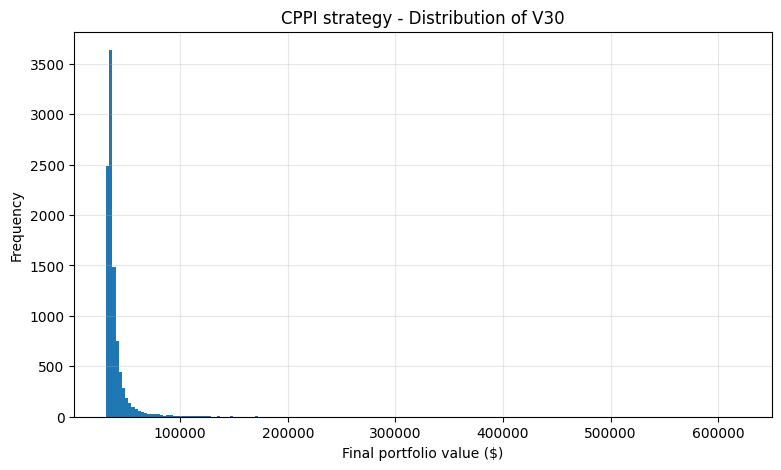

In [ ]:
#Part d
import numpy as np
import matplotlib.pyplot as plt

# Parameters
mu = 0.03
sigma = 0.20
n = 10000
T = 30

deposit = 1000
r = 0.01
r_bar = 0.005
leverage = 2

# Generate independent standard normal variables
np.random.seed(37)
Z = np.random.standard_normal((n, T))


# Simulate the CPPI strategy
def simulate_CPPI(mu, sigma, Z):

    n, T = Z.shape
    V = np.zeros(n)

    # Keep track of simulations that have fallen below the guarantee
    in_bond = np.zeros(n, dtype=bool)

    for k in range(1, T + 1):

        # Guaranteed amount after year k
        G = deposit * np.sum(np.exp(r_bar * np.arange(1, k + 1)))

        # Add the yearly deposit
        W = V + deposit

        # Stock return during year k
        R = np.exp(mu + sigma * Z[:, k - 1])

        # Simulations that are below the guarantee invest everything in bonds
        V[in_bond] = W[in_bond] * np.exp(r)

        # Simulations still following the CPPI strategy
        active = ~in_bond

        # Surplus above the discounted guarantee
        surplus = W[active] - G * np.exp(-r)

        # Invest twice the surplus in stocks
        stock = leverage * surplus

        # Invest the remaining amount in bonds
        bank = W[active] - stock

        # Calculate portfolio value at the end of the year
        V[active] = stock * R[active] + bank * np.exp(r)

        # Check which simulations have fallen below the guarantee
        in_bond = V < G

    return V


# Run the simulation
V30_d = simulate_CPPI(mu, sigma, Z)


# Calculate results
mean_value = np.mean(V30_d)
quantile_01 = np.quantile(V30_d, 0.01)
std_value = np.std(V30_d)

print("Part B(d) - CPPI strategy")
print("-------------------------")
print(f"Mean final value: ${mean_value:,.2f}")
print(f"1% quantile:      ${quantile_01:,.2f}")
print(f"Standard deviation: ${std_value:,.2f}")


# Plot histogram
plt.figure(figsize=(9, 5))

plt.hist(V30_d, bins=60)

plt.xlabel("Final portfolio value ($)")
plt.ylabel("Frequency")
plt.title("CPPI strategy - Distribution of V30")
plt.grid(alpha=0.3)

plt.show()


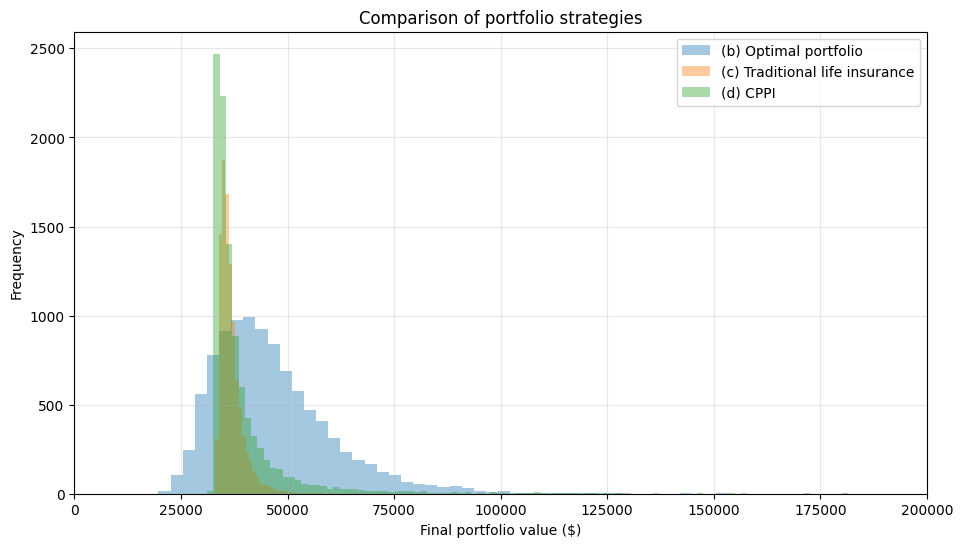

Strategy                                   Mean ($)    1% Quantile ($)
----------------------------------------------------------------------
Part (b): Optimal portfolio               46,448.21          25,008.03
Part (c): Traditional life insurance       36,814.41          33,614.47
Part (d): CPPI                            39,916.21          32,801.47


In [55]:
#COMPARE HISTOGRAMS

plt.figure(figsize=(11, 6))

plt.hist(V30_b, bins=50, alpha=0.4,
         label="(b) Optimal portfolio")

plt.hist(V30_c, bins=50, alpha=0.4,
         label="(c) Traditional life insurance")

plt.hist(V30_d, bins=400, alpha=0.4,
         label="(d) CPPI")

plt.xlabel("Final portfolio value ($)")
plt.ylabel("Frequency")
plt.title("Comparison of portfolio strategies")
plt.legend()
plt.grid(alpha=0.3)
plt.xlim(0, 200000)
plt.show()


# Calculate and compare results

strategies = {
    "Part (b): Optimal portfolio": V30_b,
    "Part (c): Traditional life insurance": V30_c,
    "Part (d): CPPI": V30_d
}

print(f"{'Strategy':<35} {'Mean ($)':>15} {'1% Quantile ($)':>18}")
print("-" * 70)

for name, values in strategies.items():
    mean_value = np.mean(values)
    quantile_01 = np.quantile(values, 0.01)

    print(f"{name:<35} {mean_value:>15,.2f} {quantile_01:>18,.2f}")
